# Bout discretization

Notebook walks step by step through discretization the 30fps original tracking data to a bout per bout basis, the bout-detection method is heavily inspired by **Le Goc et al. 2021** (*Thermal modulation of Zebrafish exploratory statistics*, BMC Biology, doi:10.1186/s12915-021-01126-w). 



## 1. Imports, constants, and locating the data

In [59]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

# ---- constants (match scripts/segment_bouts.py) ----
FPS = 30.0
# PIXEL-NATIVE: distances/positions are reported in PIXELS. We do NOT scale per
# fish (the ROIdef radius is trajectory-derived, not a physical dish measurement,
# so 50/radius has no independent basis). A single global nominal PX_PER_MM is
# used only to (a) convert Le Goc's physical thresholds to px and (b) emit a
# nominal-mm column. Angles/dtheta/HMM are scale-free regardless.
PX_PER_MM = 3.67               # repo nominal projector scale (transformed_data_pipeline.py)
POS_SMOOTH_SIGMA = 2.0         # Gaussian trajectory smoothing (frames) for heading
BOUT_LEAD_FR = round(0.08 * FPS)   # 80 ms before peak -> onset (=2 frames)
REFRACTORY_FR = round(0.40 * FPS)  # min frames between bouts (=12)
DISP_WIN_FR = round(0.50 * FPS)    # +/- displacement window (=15), centred on the PEAK
DISP_MIN_MM, DISP_MAX_MM = 0.3, 25.0        # Le Goc physical gate (documentation)
DISP_MIN_PX = DISP_MIN_MM * PX_PER_MM       # = 1.101 px (gate applied in pixels)
DISP_MAX_PX = DISP_MAX_MM * PX_PER_MM       # = 91.75 px
WALL_SHELL_PX = 5.0 * PX_PER_MM             # = 18.35 px (Le Goc 5 mm near-wall shell)
SMOOTH_FR = 3                  # speed smoothing (frames)
FORWARD_THRESH_DEG = 10.0      # |dtheta| < 10 deg -> forward (Le Goc / HMM)
STIM_NONE = {"none", "inter_stim_pause", "bout", "None", None}

# ---- locate repo data whether we run from notebooks/ or repo root ----
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
INPUT_DIR = ROOT / "data" / "data" / "df_transformed"
ROI_PATH = ROOT / "data" / "data" / "ROIdef.csv"
OUT_CSV = ROOT / "data" / "bouts_GsizeMotionSingle.csv"
csvs = sorted(INPUT_DIR.glob("*_transformed_abs.csv"))
print(f"ROOT       : {ROOT}")
print(f"per-fish csvs found: {len(csvs)}")
print(csvs[0].name if csvs else "(none)")

ROOT       : c:\Users\arthu\mp_semiCL_behavior
per-fish csvs found: 15
2025.02.20_GsizeMotionSingle_f0_transformed_abs.csv


## 2. raw input

Each row is one **frame** (30 fps). The fish never moves much per frame, we load one fish to inspect the structure and value ranges.

In [60]:
df0 = pd.read_csv(csvs[0])
prefix0 = next(re.match(r"(f\d+)_x$", c).group(1) for c in df0.columns if re.match(r"(f\d+)_x$", c))
print("shape:", df0.shape, "| fish prefix:", prefix0)
print("duration:", round(len(df0) / FPS / 60, 1), "min")
display(df0[["frame", "stimulus", f"{prefix0}_x", f"{prefix0}_y", f"{prefix0}_ori"]].head())
for c in [f"{prefix0}_x", f"{prefix0}_y", f"{prefix0}_ori"]:
    s = df0[c]
    print(f"{c}: min={np.nanmin(s):.2f} max={np.nanmax(s):.2f} nan_frac={s.isna().mean():.4f} integer={np.allclose(s.dropna(), s.dropna().round())}")
print("\nstimulus blocks (top):", df0["stimulus"].value_counts().head(6).to_dict())

shape: (313500, 29) | fish prefix: f0
duration: 174.2 min


,frame,stimulus,f0_x,f0_y,f0_ori
0,0,inter_stim_pause,NaN,NaN,NaN
1,1,inter_stim_pause,NaN,NaN,NaN
2,2,inter_stim_pause,NaN,NaN,NaN
3,3,inter_stim_pause,NaN,NaN,NaN
4,4,inter_stim_pause,NaN,NaN,NaN


f0_x: min=105.00 max=323.00 nan_frac=0.0005 integer=True
f0_y: min=122.00 max=339.00 nan_frac=0.0005 integer=True
f0_ori: min=0.00 max=6.28 nan_frac=0.0005 integer=False

stimulus blocks (top): {'inter_stim_pause': 142500, 'CLsemi1800_g4-0_s3.5-3.5': 10800, 'CLsemi1800_g0-2_s3.5-3.5': 10800, 'CLsemi1800_g0-4_s3.5-3.5': 10800, 'CLsemi1800_g8-0_s3.5-3.5': 10800, 'CLsemi1800_g0-4_s0-0': 10800}


**Two things to note**:
1. `f{N}_x/_y` are integer pixels.
2. The `stimulus` column alternates between `inter_stim_pause` (50 s) and `CLsemi...` stimulus blocks (60 s).

## 3. Units: we work in pixels

In [61]:
roi = pd.read_csv(ROI_PATH, header=None,
                  names=["xoff", "yoff", "diameter", "x", "y", "radius"])
print(f"nominal scale for the interpretability column: PX_PER_MM = {PX_PER_MM} "
      f"(distance_nominal_mm = distance_px / {PX_PER_MM})")

nominal scale for the interpretability column: PX_PER_MM = 3.67 (distance_nominal_mm = distance_px / 3.67)


### 3b. Where did each fish actually go? 

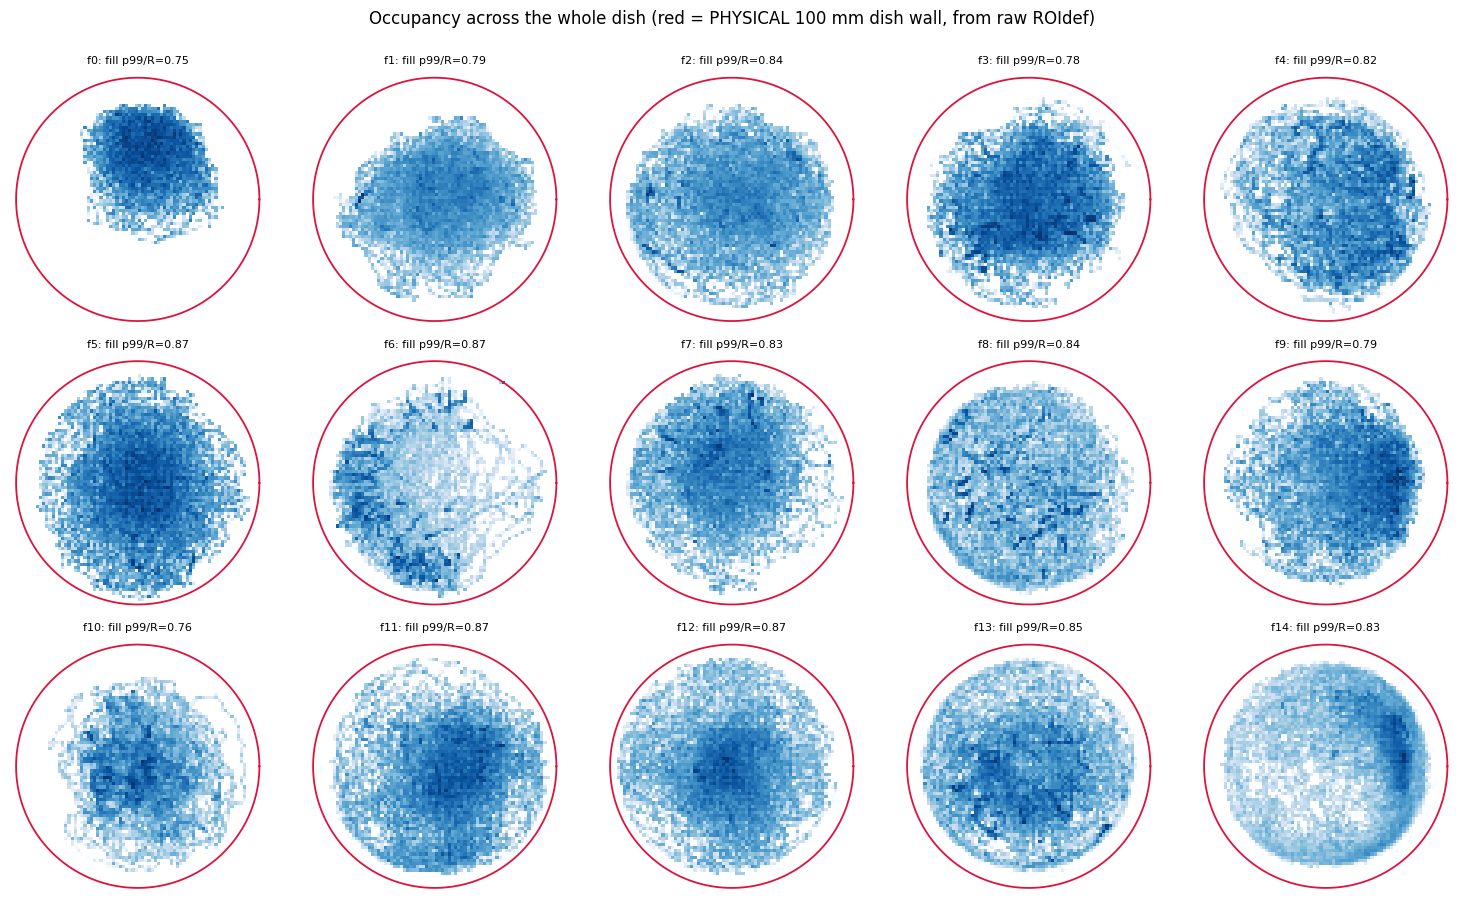

physical dish radius : mean 177.9 px  (~50 mm at 3.60 px/mm)
explored p99 / wall  : mean 0.82  (fish fill ~82% of the real dish)
frames beyond wall   : mean 0.00%  (~0 => red circle is the true boundary)


In [62]:
from matplotlib.colors import LogNorm

roi_phys = pd.read_csv(ROOT / 'data' / 'data' / 'Original_data' / 'ROIdef2025-02-20T12_09_16.csv',
                       header=None, names=['xoff', 'yoff', 'diameter', 'x', 'y', 'radius'])
roi_phys['cx'] = roi_phys['x'] - roi_phys['xoff']
roi_phys['cy'] = roi_phys['diameter'] - (roi_phys['y'] - roi_phys['yoff'])
PX_PER_MM_PHYS = roi_phys['diameter'].mean() / 100.0          # 100 mm dish -> ~3.60 px/mm

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
fill, frac_out = [], []
th = np.linspace(0, 2 * np.pi, 200)
for fid in range(15):
    fdf = pd.read_csv(INPUT_DIR / f'2025.02.20_GsizeMotionSingle_f{fid}_transformed_abs.csv',
                      usecols=[f'f{fid}_x', f'f{fid}_y'])
    x = fdf[f'f{fid}_x'].dropna().to_numpy(); y = fdf[f'f{fid}_y'].dropna().to_numpy()
    cx, cy, r_phys = roi_phys.loc[fid, 'cx'], roi_phys.loc[fid, 'cy'], roi_phys.loc[fid, 'radius']
    r = np.hypot(x - cx, y - cy)
    fill.append(np.quantile(r, 0.99) / r_phys)               # how much of the dish is used
    frac_out.append(np.mean(r > r_phys))                     # should be ~0 (fish stay inside)
    ax = axes.flat[fid]
    lim = 1.05 * r_phys                                       # dish-centred on the PHYSICAL centre
    ax.hist2d(x, y, bins=80, range=[[cx - lim, cx + lim], [cy - lim, cy + lim]],
              cmap='Blues', cmin=1, norm=LogNorm())
    ax.plot(cx + r_phys * np.cos(th), cy + r_phys * np.sin(th), '-', color='crimson', lw=1.3)  # physical wall
    ax.set_xlim(cx - lim, cx + lim); ax.set_ylim(cy - lim, cy + lim)
    ax.set_title(f'f{fid}: fill p99/R={fill[-1]:.2f}', fontsize=8)
    ax.set_aspect('equal'); ax.axis('off')
plt.suptitle('Occupancy across the whole dish (red = PHYSICAL 100 mm dish wall, from raw ROIdef)', y=1.0)
plt.tight_layout(); plt.show()
r_mean = roi_phys['radius'].mean()
print(f'physical dish radius : mean {r_mean:.1f} px  (~50 mm at {PX_PER_MM_PHYS:.2f} px/mm)')
print(f'explored p99 / wall  : mean {np.mean(fill):.2f}  (fish fill ~{100*np.mean(fill):.0f}% of the real dish)')
print(f'frames beyond wall   : mean {100*np.mean(frac_out):.2f}%  (~0 => red circle is the true boundary)')

## 4. Helper functions

These mirror `scripts/segment_bouts.py`. We define them inline so each step is visible.

In [63]:
def wrap_pi(a):
    """Wrap angle(s) to (-pi, pi]."""
    return (np.asarray(a) + np.pi) % (2 * np.pi) - np.pi


def parse_stimulus(name):
    """Parse 'CLsemi1800_g{L}-{R}_s{sL}-{sR}' into stimulus-context fields."""
    out = dict(n_dots_left=np.nan, n_dots_right=np.nan,
               speed_left=np.nan, speed_right=np.nan, side="none", moving=False)
    if not isinstance(name, str) or not name.startswith("CLsemi"):
        return out
    mg = re.search(r"_g(\d+)-(\d+)", name)
    ms = re.search(r"_s([\d.]+)-([\d.]+)", name)
    if mg:
        L, R = int(mg.group(1)), int(mg.group(2))
        out["n_dots_left"], out["n_dots_right"] = L, R
        out["side"] = ("left" if L > 0 and R == 0 else
                       "right" if R > 0 and L == 0 else
                       "both" if L > 0 and R > 0 else "none")
    if ms:
        out["speed_left"], out["speed_right"] = float(ms.group(1)), float(ms.group(2))
        out["moving"] = (out["speed_left"] > 0) or (out["speed_right"] > 0)
    return out


def stim_angle_at(row, fx, fy, f_ori, n_stimuli=8):
    """Angle (rad, relative to fish facing f_ori) of the active-dot centroid."""
    xs, ys = [], []
    for k in range(n_stimuli):
        sc, xc, yc = f"d{k}_stim", f"d{k}_x", f"d{k}_y"
        if sc not in row or row[sc] in STIM_NONE or pd.isna(row.get(xc)):
            continue
        xs.append(row[xc]); ys.append(row[yc])
    if not xs:
        return np.nan
    return float(wrap_pi(np.arctan2(np.mean(ys) - fy, np.mean(xs) - fx) - f_ori))


def fish_xy_px(seg, prefix):
    """Sub-pixel-smoothed position (px). Smoothing fights the integer-pixel
    quantisation that otherwise spawns spurious speed peaks -- it is used for
    BOUT DETECTION only; heading/distance/position are measured from the raw
    pixel positions (see segment_fish), so smoothing never biases the direction."""
    x = seg[f"{prefix}_x"].to_numpy(dtype=float)
    y = seg[f"{prefix}_y"].to_numpy(dtype=float)
    if POS_SMOOTH_SIGMA > 0 and len(x) > 3:
        x = gaussian_filter1d(x, POS_SMOOTH_SIGMA)
        y = gaussian_filter1d(y, POS_SMOOTH_SIGMA)
    return x, y


def speed_px_s(x, y):
    """Instantaneous speed (px/s), lightly smoothed."""
    v = np.concatenate([[0.0], np.hypot(np.diff(x), np.diff(y))]) * FPS
    if SMOOTH_FR > 1:
        v = pd.Series(v).rolling(SMOOTH_FR, center=True, min_periods=1).mean().to_numpy()
    return v


def _snap_to_trough(v, p):
    """Walk back from speed peak p to the preceding local minimum (rest point)."""
    i = p
    while i > 0 and v[i - 1] <= v[i]:
        i -= 1
    return i


def detect_bouts(x, y, speed_thresh_k, onset_mode="trough"):
    """Detect bouts -> two aligned arrays (onsets, peaks).

    onset = bout START frame (timing / position / stimulus context / heading):
            'trough' = local speed minimum before the peak (default);
            'lead'   = Le Goc literal, BOUT_LEAD_FR frames before the peak.
    peak  = speed-peak frame, kept for the body-orientation cross-check.
    Positions are PIXELS; the displacement gate uses the pixel thresholds
    (DISP_MIN_PX .. DISP_MAX_PX = Le Goc 0.3-25 mm via the nominal PX_PER_MM).
    """
    n = len(x)
    if n < 2 * DISP_WIN_FR + 2:
        return np.array([], dtype=int), np.array([], dtype=int)
    v = speed_px_s(x, y)
    thr = np.nanmean(v) + speed_thresh_k * np.nanstd(v)
    peaks, _ = find_peaks(v, height=thr, distance=REFRACTORY_FR)
    if onset_mode == "trough":
        onsets = np.array([_snap_to_trough(v, p) for p in peaks], dtype=int)
    else:
        onsets = np.clip(peaks - BOUT_LEAD_FR, 0, n - 1)
    keep = []
    for o, p in zip(onsets, peaks):
        # Gate window centred on the PEAK, not the onset. In 'trough' mode the
        # onset can sit many seconds before the peak (the walk-back crosses a
        # flat stationary stretch -- quiescence), which would put the +/-0.5 s
        # window entirely inside the still period and read ~0 travel for a
        # perfectly real bout. The burst being tested is the one at the peak.
        a, b = max(p - DISP_WIN_FR, 0), min(p + DISP_WIN_FR, n - 1)
        if DISP_MIN_PX <= np.hypot(x[b] - x[a], y[b] - y[a]) <= DISP_MAX_PX:
            keep.append((o, p))
    if not keep:
        return np.array([], dtype=int), np.array([], dtype=int)
    keep.sort()
    on = np.array([k[0] for k in keep]); pk = np.array([k[1] for k in keep])
    _, idx = np.unique(on, return_index=True)   # drop rare duplicate onsets
    return on[idx], pk[idx]


print("helpers defined.")

helpers defined.


## 5. Step-through on ONE stimulus block — speed trace and detected bouts

We pick one `CLsemi...` block of fish 0, compute the speed, and mark each bout. Two anchors per bout:
- **green ● = onset (trough)** — the speed minimum *before* the burst, i.e. where the fish starts accelerating (the physical bout start). Used for timing, position, stimulus context, and as the heading/distance anchor.
- **red ▾ = speed peak** — the active phase of the bout. Kept for the body-orientation cross-check and the per-bout speed readout.

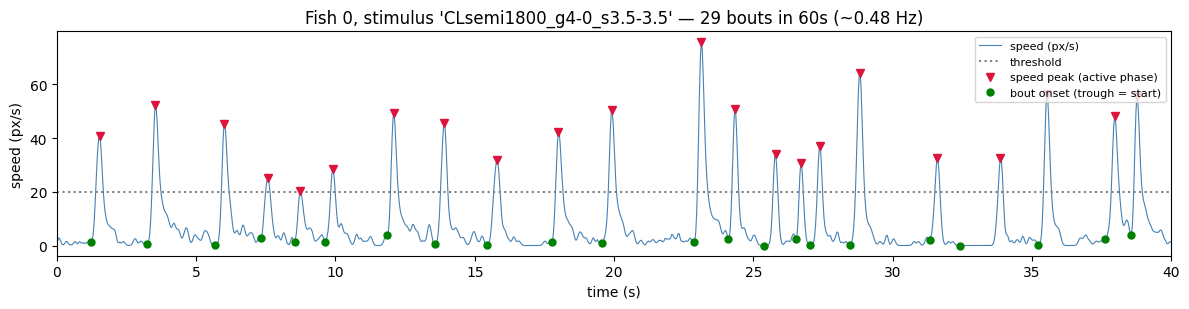

In [64]:
K = 1.0   # speed threshold factor (mean + K*std)

# take the first long CLsemi block of fish 0
blk = (df0["stimulus"] != df0["stimulus"].shift()).cumsum()
cand = df0.assign(_b=blk).groupby("_b").filter(
    lambda g: g["stimulus"].iloc[0].startswith("CLsemi") and len(g) > 600)
seg = cand[cand["_b"] == cand["_b"].iloc[0]].reset_index(drop=True)

# smoothed positions -> DETECTION only (locate the onset/peak frames). The raw
# positions (xr, yr) are what we plot and measure heading from further down.
x, y = fish_xy_px(seg, prefix0)
v = speed_px_s(x, y)
onsets, peaks = detect_bouts(x, y, K)   # onset = trough (bout start), peak = active phase
xr = seg[f"{prefix0}_x"].to_numpy(float)   # raw (unsmoothed) px
yr = seg[f"{prefix0}_y"].to_numpy(float)
t = np.arange(len(v)) / FPS

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(t, v, lw=0.8, color="steelblue", label="speed (px/s)")
ax.axhline(np.nanmean(v) + K * np.nanstd(v), color="gray", ls=":", label="threshold")
ax.plot(peaks / FPS, v[peaks], "v", color="crimson", ms=6, label="speed peak (active phase)")
ax.plot(onsets / FPS, v[onsets], "o", color="green", ms=5, label="bout onset (trough = start)")
ax.set_xlim(0, min(40, t[-1])); ax.set_xlabel("time (s)"); ax.set_ylabel("speed (px/s)")
ax.set_title(f"Fish 0, stimulus '{seg['stimulus'].iloc[0]}' — {len(onsets)} bouts in {len(seg)/FPS:.0f}s "
             f"(~{len(onsets)/(len(seg)/FPS):.2f} Hz)")
ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

## 6. The same block in 2D — trajectory coloured by bout

Each detected bout onset is a point along the path. This is the discretisation: a continuous track becomes a sequence of bouts.

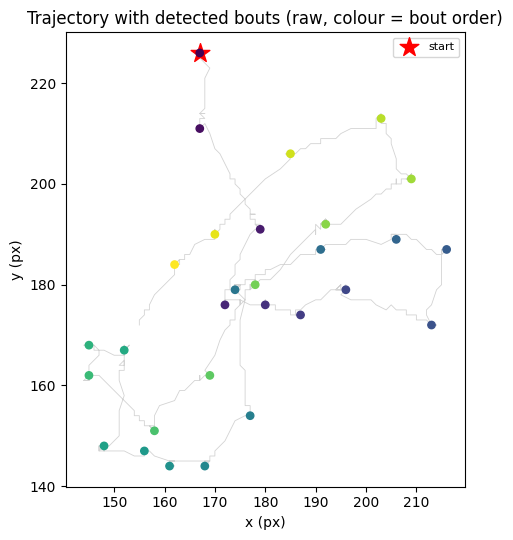

In [65]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(xr, yr, lw=0.6, color="lightgray", zorder=1)                          # raw path
ax.scatter(xr[onsets], yr[onsets], c=np.arange(len(onsets)), cmap="viridis", s=28, zorder=2)
ax.scatter([xr[onsets[0]]], [yr[onsets[0]]], marker="*", s=200, color="red", label="start")
ax.set_aspect("equal"); ax.set_xlabel("x (px)"); ax.set_ylabel("y (px)")
ax.set_title("Trajectory with detected bouts (raw, colour = bout order)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 6b. Same trajectory — heading arrows over the **raw** path, coloured by speed

The same block, but each bout is an **arrow in its travel direction** over the **raw (unsmoothed) trajectory**, coloured by the **bout's speed**. Heading is taken **onset-to-onset** from the raw bout positions (`θᵢ = dir(onsetᵢ₊₁ − onsetᵢ)`), so each arrow points from this bout to the next — the direction the fish actually goes until the next bout. Smoothing was used only to *detect* the bouts (find the onset/peak frames), never to compute these positions or arrows.

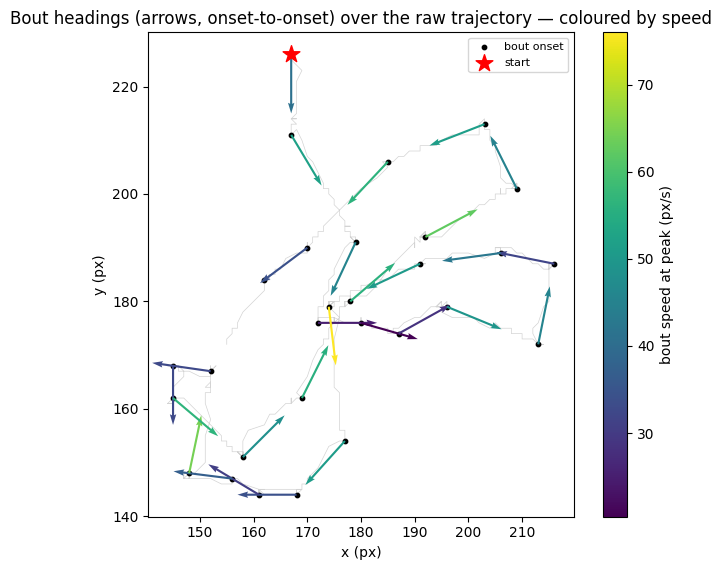

In [66]:
# Each bout drawn as a heading ARROW pointing to the NEXT bout, over the RAW
# (unsmoothed) trajectory. Heading is onset-to-onset from the raw discretized bout
# positions: theta_i = dir(onset_{i+1} - onset_i). Smoothing was used ONLY to
# detect the bouts, never to bend these arrows. Positions in pixels.
ox, oy = xr[onsets], yr[onsets]
theta = np.arctan2(np.diff(oy), np.diff(ox))        # onset-to-onset heading (raw)
bout_speed = v[peaks][:-1]                          # speed at the peak (px/s), aligned to theta
ax0, ay0 = ox[:len(theta)], oy[:len(theta)]         # arrow origin = bout onset

L = 11.0  # arrow length (px, ~3 mm at the nominal scale)
fig, ax = plt.subplots(figsize=(6.6, 5.8))
ax.plot(xr, yr, lw=0.5, color="lightgray", zorder=1)                 # raw path
ax.scatter(ox, oy, s=10, color="k", zorder=2, label="bout onset")    # detected onsets
q = ax.quiver(ax0, ay0, L * np.cos(theta), L * np.sin(theta), bout_speed,
              angles="xy", scale_units="xy", scale=1, cmap="viridis",
              width=0.005, zorder=3)
ax.scatter([ax0[0]], [ay0[0]], marker="*", s=160, color="red", zorder=4, label="start")
fig.colorbar(q, ax=ax, label="bout speed at peak (px/s)")
ax.set_aspect("equal"); ax.set_xlabel("x (px)"); ax.set_ylabel("y (px)")
ax.set_title("Bout headings (arrows, onset-to-onset) over the raw trajectory — coloured by speed")
ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

## 7. Per-bout kinematics — heading, reorientation `dtheta`, `dt`, `distance`

Heading is read **onset-to-onset** from the **raw** bout positions (in **pixels**), so each bout's heading is the net travel to the next bout (the direction the fish actually goes until then). Computing it from the discretized positions makes it robust to where in the bout the speed peaks and to 180° head/tail flips:
- **heading** $\theta_i = \mathrm{atan2}(\,y_{\text{onset}_{i+1}}-y_{\text{onset}_i},\; x_{\text{onset}_{i+1}}-x_{\text{onset}_i})$ — scale-free, so pixels vs mm make no difference
- **reorientation** $\delta\theta_i = \mathrm{wrap}(\theta_i - \theta_{i-1})$
- **dt** and **distance** (`distance_px`, plus a nominal-mm column) are the same onset-to-onset interval and leg.

Gaussian smoothing enters **only** into detecting the onset/peak frames; every measured quantity above uses the raw positions. We also keep `dtheta_ori` (body orientation at the peak, flip-corrected) as an independent cross-check.

In [67]:
def segment_fish(df, prefix, fish_id, speed_thresh_k, split_at_blocks=False,
                 onset_mode="trough"):
    """Segment one fish into bouts -> list of per-bout dict records.

    PIXEL-NATIVE: positions/distances are reported in pixels (no per-fish scaling).
    Two anchors per bout: onset (trough) = bout START (timing, position, stimulus,
    heading/distance anchor); peak = kept for the body-orientation cross-check.
    Smoothing is used ONLY to detect bout timing; heading/distance/position are
    measured from the RAW pixel positions. Split only at tracking gaps unless
    split_at_blocks=True.
    """
    df = df.reset_index(drop=True).copy()
    has_pos = df[f"{prefix}_x"].notna() & df[f"{prefix}_y"].notna()
    edges = (~has_pos) & has_pos.shift(fill_value=False)        # tracking gaps
    if split_at_blocks:
        edges = edges | df["stimulus"].ne(df["stimulus"].shift())
    df["_seg"] = edges.cumsum()

    records = []
    for sid, seg in df.groupby("_seg", sort=True):
        seg = seg[has_pos.loc[seg.index]].reset_index(drop=True)
        if len(seg) < 2 * DISP_WIN_FR + 2:
            continue
        x, y = fish_xy_px(seg, prefix)             # smoothed -> detection only
        onsets, peaks = detect_bouts(x, y, speed_thresh_k, onset_mode=onset_mode)
        if len(onsets) < 3:
            continue
        frames = seg["frame"].to_numpy()
        ori_raw = seg[f"{prefix}_ori"].to_numpy(dtype=float)
        xr = seg[f"{prefix}_x"].to_numpy(dtype=float)   # RAW px -> everything measured
        yr = seg[f"{prefix}_y"].to_numpy(dtype=float)

        # heading & distance from RAW onset positions -> net travel to the next
        # bout; dt from the same onsets (bout starts)
        ox, oy = xr[onsets], yr[onsets]
        theta = np.arctan2(np.diff(oy), np.diff(ox))   # onset-to-onset heading (raw)
        dist = np.hypot(np.diff(ox), np.diff(oy))       # px, onset-to-onset (raw)
        dt = np.diff(frames[onsets]) / FPS              # s, onset-to-onset

        # orientation cross-check: body orientation at the peak, flip-corrected
        ori_pk = ori_raw[peaks]
        mv = np.concatenate([theta, theta[-1:]])
        ori_c = np.where(np.cos(ori_pk - mv) < 0, wrap_pi(ori_pk + np.pi), ori_pk)

        for i in range(1, len(onsets) - 1):
            o = onsets[i]; row = seg.iloc[o]; f_ori = float(ori_raw[o])
            dtheta = wrap_pi(theta[i] - theta[i - 1])
            dtheta_ori = wrap_pi(ori_c[i] - ori_c[i - 1])
            stim = row["stimulus"]; ctx = parse_stimulus(stim)   # condition at onset
            rec = dict(
                fish_id=fish_id, segment_id=int(sid), bout_index=i,
                frame_onset=int(row["frame"]), t_onset_s=float(row["frame"]) / FPS,
                dtheta_rad=float(dtheta), dtheta_deg=float(np.degrees(dtheta)),
                dtheta_ori_deg=float(np.degrees(dtheta_ori)),
                dt_s=float(dt[i]), distance_px=float(dist[i]),
                distance_nominal_mm=float(dist[i] / PX_PER_MM),
                heading_rad=float(theta[i]), f_ori_rad=f_ori,
                x_px=float(xr[o]), y_px=float(yr[o]), stimulus=stim,
                stim_angle_rad=stim_angle_at(row, xr[o], yr[o], f_ori),
                **ctx,
            )
            adeg = abs(rec["dtheta_deg"])
            rec["bout_type"] = ("forward" if adeg < FORWARD_THRESH_DEG
                                else ("left" if dtheta > 0 else "right"))
            records.append(rec)
    return records


# demo on fish 0
rec0 = segment_fish(df0, prefix0, 0, K)
print(f"fish 0: {len(rec0)} bouts")
pd.DataFrame(rec0).head()

fish 0: 4620 bouts


,fish_id,segment_id,bout_index,frame_onset,t_onset_s,dtheta_rad,dtheta_deg,dtheta_ori_deg,dt_s,distance_px,...,y_px,stimulus,stim_angle_rad,n_dots_left,n_dots_right,speed_left,speed_right,side,moving,bout_type
0,0,0,1,218,7.266667,-0.965252,-55.304846,-73.224006,2.900000,26.870058,...,191.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,right
1,0,0,2,305,10.166667,0.680521,38.990994,31.913749,2.766667,19.104973,...,210.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,left
2,0,0,3,388,12.933333,-0.402222,-23.045598,-14.553128,0.933333,10.295630,...,229.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,right
3,0,0,4,416,13.866667,-0.033321,-1.909152,-2.750197,1.566667,11.661904,...,238.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,forward
4,0,0,5,463,15.433333,-0.047583,-2.726311,1.145916,11.866667,10.816654,...,248.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,forward


## 8. Run on all 15 fish and assemble the bout dataframe

In [68]:
all_records = []
for path in csvs:
    m = re.search(r"_f(\d+)_transformed_abs", path.name)
    fid = int(m.group(1)) if m else -1
    dfi = pd.read_csv(path)
    pref = next(re.match(r"(f\d+)_x$", c).group(1) for c in dfi.columns if re.match(r"(f\d+)_x$", c))
    recs = segment_fish(dfi, pref, fid, K)
    all_records.extend(recs)
    print(f"  fish {fid:>2}: {len(recs):>5} bouts")

bouts = pd.DataFrame(all_records)
print("\ntotal bouts:", len(bouts))
bouts.head()

  fish  0:  4620 bouts
  fish 10:  3162 bouts
  fish 11:  6198 bouts
  fish 12:  5721 bouts
  fish 13:  3892 bouts
  fish 14:  4748 bouts
  fish  1:  5366 bouts
  fish  2:  5639 bouts
  fish  3:  4850 bouts
  fish  4:  3292 bouts
  fish  5:  6842 bouts
  fish  6:  3185 bouts
  fish  7:  6505 bouts
  fish  8:  3265 bouts
  fish  9:  4648 bouts

total bouts: 71933


,fish_id,segment_id,bout_index,frame_onset,t_onset_s,dtheta_rad,dtheta_deg,dtheta_ori_deg,dt_s,distance_px,...,y_px,stimulus,stim_angle_rad,n_dots_left,n_dots_right,speed_left,speed_right,side,moving,bout_type
0,0,0,1,218,7.266667,-0.965252,-55.304846,-73.224006,2.900000,26.870058,...,191.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,right
1,0,0,2,305,10.166667,0.680521,38.990994,31.913749,2.766667,19.104973,...,210.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,left
2,0,0,3,388,12.933333,-0.402222,-23.045598,-14.553128,0.933333,10.295630,...,229.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,right
3,0,0,4,416,13.866667,-0.033321,-1.909152,-2.750197,1.566667,11.661904,...,238.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,forward
4,0,0,5,463,15.433333,-0.047583,-2.726311,1.145916,11.866667,10.816654,...,248.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,forward


### Physical distance-to-border feature

A **pixel-native, scale-free** feature for boundary-aware models: for each bout onset,
the distance to the **physical** dish wall (from the raw ROIdef). `dist_to_border_px = R - r`
and `dist_to_border_norm = (R - r)/R` in [0,1] (1 at the centre, 0 at the wall), where
`r` is the distance from the physical dish centre and `R` the physical radius.

In [69]:
# Physical distance-to-nearest-border feature (PIXEL-NATIVE, scale-free), from the
# RAW ROIdef (true 100 mm dish wall), mapped into this y-flipped frame:
#   centre=(x-xoff, diameter-(y-yoff)), radius unchanged; row i = fish i.
#   dist_to_border_px   = R - r         (~0 at the wall, ~R at the centre)
#   dist_to_border_norm = (R - r) / R   (1 centre -> 0 wall; exact, unit-free)
# Uses the PHYSICAL dish, unlike near_wall (each fish's own median centre + p95 radius);
# the two diverge for off-centre fish (f0/f6/f14). Mirrors scripts/segment_bouts.py.
roi_phys = pd.read_csv(ROOT / 'data' / 'data' / 'Original_data' / 'ROIdef2025-02-20T12_09_16.csv',
                       header=None, names=['xoff', 'yoff', 'diameter', 'x', 'y', 'radius'])
roi_phys['cx'] = roi_phys['x'] - roi_phys['xoff']
roi_phys['cy'] = roi_phys['diameter'] - (roi_phys['y'] - roi_phys['yoff'])
cx = bouts['fish_id'].map(roi_phys['cx']); cy = bouts['fish_id'].map(roi_phys['cy'])
R = bouts['fish_id'].map(roi_phys['radius'])
r = np.hypot(bouts['x_px'] - cx, bouts['y_px'] - cy)
bouts['dist_to_border_px'] = (R - r).astype(float)
bouts['dist_to_border_norm'] = ((R - r) / R).astype(float)
print('dist_to_border_norm: min %.3f  max %.3f  | %d bouts, no NaN=%s'
      % (bouts['dist_to_border_norm'].min(), bouts['dist_to_border_norm'].max(),
         len(bouts), bool(bouts[['dist_to_border_px', 'dist_to_border_norm']].isna().sum().sum() == 0)))

dist_to_border_norm: min 0.007  max 1.000  | 71933 bouts, no NaN=True


### Active-dot geometry — `dot_dist_px`

The stimulus analogue of the border feature above: how far the fish was from the **centroid
of the dots that were on** at each bout onset.


In [70]:
# Per-bout ACTIVE-DOT geometry -- the stimulus analogue of dist_to_border above:
#   dot_cx, dot_cy  = centroid of the dots that are ON at the bout onset (px)
#   dot_dist_px     = fish onset pose (x_px, y_px) -> that centroid
#   dot_prox        = 1 / (1 + (dot_dist_px/PX_PER_MM)/R0_MM)   retinal-size weight
# NaN on bouts with no active dot (the inter-stimulus pauses). Same active-dot rule
# (STIM_NONE) and centroid convention as stim_angle_at, and it uses the bout's own
# x_px/y_px so it matches the pose the models seed from.
#
# Mirrors scripts/segment_bouts.add_dist_to_dot, which the CLI applies as a separate
# pass (scripts/add_dot_geometry.py). Doing it here keeps this notebook a COMPLETE
# producer of the bouts CSV -- without it Data_Exploration's approach curves have no
# dot_dist_px and raise KeyError.
R0_MM = 20.0        # proximity softening (mm); matches fit_hmm_stim's retinal-size weight
N_STIMULI = 8

for _c in ("dot_cx", "dot_cy", "dot_dist_px", "dot_prox"):
    bouts[_c] = np.nan

_cols = ["frame"] + [f"d{k}_{s}" for k in range(N_STIMULI) for s in ("x", "y", "stim")]
for fid, grp in bouts.groupby("fish_id"):
    cands = sorted(INPUT_DIR.glob(f"*_f{int(fid)}_transformed_abs.csv"))
    if not cands:
        continue
    fdf = pd.read_csv(cands[0], usecols=_cols).sort_values("frame").reset_index(drop=True)
    row_of = {int(f): i for i, f in enumerate(fdf["frame"].to_numpy(int))}
    DX = np.stack([fdf[f"d{k}_x"].to_numpy(float) for k in range(N_STIMULI)], axis=1)
    DY = np.stack([fdf[f"d{k}_y"].to_numpy(float) for k in range(N_STIMULI)], axis=1)
    ACT = np.stack([(~fdf[f"d{k}_stim"].astype(str).isin(STIM_NONE).to_numpy())
                    & np.isfinite(DX[:, k]) for k in range(N_STIMULI)], axis=1)
    for idx, fo in grp["frame_onset"].items():
        i = row_of.get(int(fo))
        if i is None:
            continue
        m = ACT[i]
        if not m.any():
            continue
        dcx, dcy = float(np.mean(DX[i][m])), float(np.mean(DY[i][m]))
        dd = float(np.hypot(float(bouts.at[idx, "x_px"]) - dcx,
                            float(bouts.at[idx, "y_px"]) - dcy))
        bouts.at[idx, "dot_cx"] = dcx
        bouts.at[idx, "dot_cy"] = dcy
        bouts.at[idx, "dot_dist_px"] = dd
        bouts.at[idx, "dot_prox"] = 1.0 / (1.0 + (dd / PX_PER_MM) / R0_MM)

_have = int(bouts["dot_dist_px"].notna().sum())
print(f"dot geometry: {_have}/{len(bouts)} bouts have an active dot at onset "
      f"({100 * _have / len(bouts):.1f} %)")
print(f"  dot_dist_px  median {bouts['dot_dist_px'].median():.1f} px  "
      f"max {bouts['dot_dist_px'].max():.1f} px")
print("  new columns:", [c for c in ("dot_cx", "dot_cy", "dot_dist_px", "dot_prox")])


dot geometry: 40873/71933 bouts have an active dot at onset (56.8 %)
  dot_dist_px  median 71.7 px  max 394.2 px
  new columns: ['dot_cx', 'dot_cy', 'dot_dist_px', 'dot_prox']


## 8b. Trajectory structure — how many bouts per fish

fish                          : 15
trajectories (fish, segment)  : 15
segments per fish             : min 1, max 1  -> one per fish: tracking never broke
bouts per trajectory          : min 3162, median 4748, mean 4796, max 6842
duration per trajectory [min] : min 168.4, median 173.2, max 174.0  (~full ~174 min session)
trajectories with >=10 bouts (used by the HMMs): 15 / 15
total                         : 71933 bouts over 43.2 fish-hours
(rate_Hz is the average over the whole trajectory incl. idle stretches; the ~0.81 Hz in Sect. 9 is 1/median(dt), the typical instantaneous rate.)


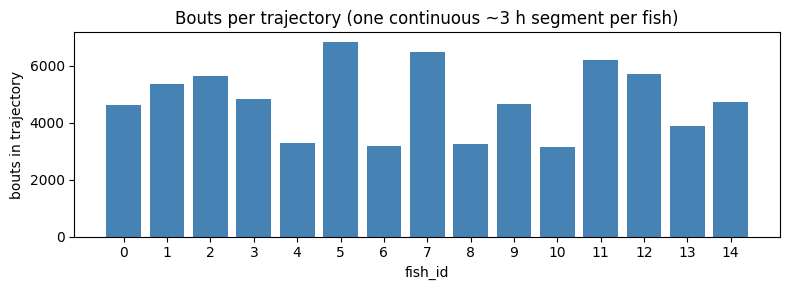

,fish_id,segment_id,n_bouts,dur_min,rate_Hz
0,0,0,4620,174.0,0.44
1,1,0,5366,173.2,0.52
2,2,0,5639,174.0,0.54
3,3,0,4850,173.2,0.47
4,4,0,3292,173.1,0.32
5,5,0,6842,173.0,0.66
6,6,0,3185,171.9,0.31
7,7,0,6505,173.6,0.62
8,8,0,3265,173.1,0.31
9,9,0,4648,173.9,0.45


In [71]:
# Trajectory = a continuous tracked segment. The stream is split ONLY at tracking
# gaps (NaN fish positions), never at stimulus/pause boundaries. Below: how many
# trajectories resulted, how long they are, and how many bouts each holds.
traj = bouts.groupby(["fish_id", "segment_id"])
per = traj.agg(
    n_bouts=("bout_index", "size"),
    dur_min=("t_onset_s", lambda s: (s.max() - s.min()) / 60),   # first-to-last bout
).reset_index()
per["rate_Hz"] = per["n_bouts"] / (per["dur_min"] * 60)          # avg over the trajectory
seg_per_fish = bouts.groupby("fish_id")["segment_id"].nunique()

print(f"fish                          : {bouts['fish_id'].nunique()}")
print(f"trajectories (fish, segment)  : {len(per)}")
print(f"segments per fish             : min {seg_per_fish.min()}, max {seg_per_fish.max()}"
      + ("  -> one per fish: tracking never broke" if seg_per_fish.max() == 1
         else "  -> gaps split some fish"))
print(f"bouts per trajectory          : min {per.n_bouts.min()}, median {per.n_bouts.median():.0f}, "
      f"mean {per.n_bouts.mean():.0f}, max {per.n_bouts.max()}")
print(f"duration per trajectory [min] : min {per.dur_min.min():.1f}, median {per.dur_min.median():.1f}, "
      f"max {per.dur_min.max():.1f}  (~full ~174 min session)")
print(f"trajectories with >=10 bouts (used by the HMMs): {(per.n_bouts >= 10).sum()} / {len(per)}")
print(f"total                         : {len(bouts)} bouts over {per.dur_min.sum()/60:.1f} fish-hours")
print("(rate_Hz is the average over the whole trajectory incl. idle stretches; the "
      "~0.81 Hz in Sect. 9 is 1/median(dt), the typical instantaneous rate.)")

fig, ax = plt.subplots(figsize=(8, 3.0))
o = per.sort_values("fish_id")
ax.bar(o["fish_id"].astype(str), o["n_bouts"], color="steelblue")
ax.set_xlabel("fish_id"); ax.set_ylabel("bouts in trajectory")
ax.set_title("Bouts per trajectory (one continuous ~3 h segment per fish)")
plt.tight_layout(); plt.show()

display(per.assign(dur_min=per["dur_min"].round(1), rate_Hz=per["rate_Hz"].round(2)))

## 9. Stimulus context — does the side of the dots bias turning?

Each bout carries the active stimulus. Here we compare the mean **signed reorientation** (positive = leftward turn) for bouts during left-only vs right-only dot stimuli. This is the kind of question this segmented dataset enables.

,count,mean,median
side,,,
left,20941,0.85,0.78
right,19932,-1.32,-1.99


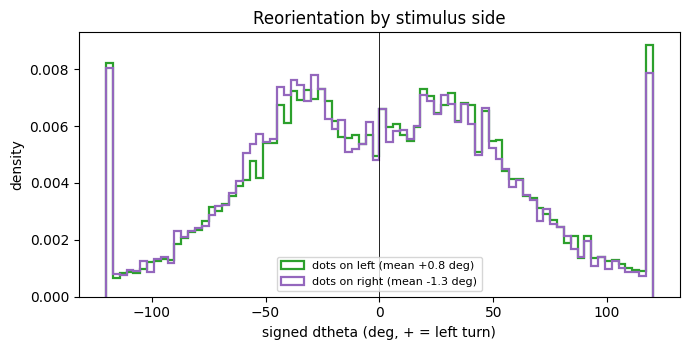

In [72]:
stim_bouts = bouts[(bouts["side"].isin(["left", "right"]))]
summary = stim_bouts.groupby("side")["dtheta_deg"].agg(["count", "mean", "median"]).round(2)
display(summary)

fig, ax = plt.subplots(figsize=(7, 3.6))
for side, c in [("left", "tab:green"), ("right", "tab:purple")]:
    d = stim_bouts.loc[stim_bouts["side"] == side, "dtheta_deg"]
    ax.hist(d.clip(-120, 120), bins=80, histtype="step", lw=1.6, density=True, color=c,
            label=f"dots on {side} (mean {d.mean():+.1f} deg)")
ax.axvline(0, color="k", lw=0.6); ax.set_xlabel("signed dtheta (deg, + = left turn)")
ax.set_ylabel("density"); ax.set_title("Reorientation by stimulus side")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 10. Save the bout dataset

In [73]:
OUT_CSV.parent.mkdir(parents=True, exist_ok=True)
bouts.to_csv(OUT_CSV, index=False)
print(f"saved {len(bouts)} bouts -> {OUT_CSV}")
print("columns:", list(bouts.columns))

saved 71933 bouts -> c:\Users\arthu\mp_semiCL_behavior\data\bouts_GsizeMotionSingle.csv
columns: ['fish_id', 'segment_id', 'bout_index', 'frame_onset', 't_onset_s', 'dtheta_rad', 'dtheta_deg', 'dtheta_ori_deg', 'dt_s', 'distance_px', 'distance_nominal_mm', 'heading_rad', 'f_ori_rad', 'x_px', 'y_px', 'stimulus', 'stim_angle_rad', 'n_dots_left', 'n_dots_right', 'speed_left', 'speed_right', 'side', 'moving', 'bout_type', 'dist_to_border_px', 'dist_to_border_norm', 'dot_cx', 'dot_cy', 'dot_dist_px', 'dot_prox']


In [74]:
bouts

,fish_id,segment_id,bout_index,frame_onset,t_onset_s,dtheta_rad,dtheta_deg,dtheta_ori_deg,dt_s,distance_px,...,speed_right,side,moving,bout_type,dist_to_border_px,dist_to_border_norm,dot_cx,dot_cy,dot_dist_px,dot_prox
0,0,0,1,218,7.266667,-0.965252,-55.304846,-73.224006,2.900000,26.870058,...,NaN,none,False,right,118.000000,0.624339,NaN,NaN,NaN,NaN
1,0,0,2,305,10.166667,0.680521,38.990994,31.913749,2.766667,19.104973,...,NaN,none,False,left,133.637558,0.707077,NaN,NaN,NaN,NaN
2,0,0,3,388,12.933333,-0.402222,-23.045598,-14.553128,0.933333,10.295630,...,NaN,none,False,right,126.198726,0.667718,NaN,NaN,NaN,NaN
3,0,0,4,416,13.866667,-0.033321,-1.909152,-2.750197,1.566667,11.661904,...,NaN,none,False,forward,123.930806,0.655719,NaN,NaN,NaN,NaN
4,0,0,5,463,15.433333,-0.047583,-2.726311,1.145916,11.866667,10.816654,...,NaN,none,False,forward,119.934813,0.634576,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71928,9,0,4644,313106,10436.866667,-1.211284,-69.401445,-69.911468,2.600000,34.132096,...,3.5,right,True,right,129.902278,0.738081,103.187222,164.808451,33.050605,0.689522
71929,9,0,4645,313184,10439.466667,-1.302935,-74.652702,-67.322541,1.366667,22.360680,...,3.5,right,True,right,164.000000,0.931818,126.683309,154.695759,45.704375,0.616266
71930,9,0,4646,313225,10440.833333,2.176341,124.695154,101.767922,0.866667,19.798990,...,3.5,right,True,left,152.590600,0.866992,136.957154,153.326067,33.150862,0.688873
71931,9,0,4647,313251,10441.700000,-0.628796,-36.027373,-15.985522,3.166667,38.470768,...,3.5,right,True,right,166.000000,0.943182,141.143284,139.153093,52.803691,0.581599



- The batch script equivalent of this notebook is `scripts/segment_bouts.py`.